# Population Coverage by region

This will work to indentify the population coverage (people with service vs people with no service) by region

In [1]:
# Libraries import code
import ast
import io
import matplotlib.pyplot as plt
import pandas as pd
import requests
import seaborn as sns

# datasets/dataframes to be used
url = "https://1drv.ms/x/c/a2d8e070eb2474a8/IQCs4lZ_juBDS4S53YwSiAPGAYwBr-vaTmPi87dZZQ1yR-U?e=xuOuI5&download=1"
telecom_datos = pd.read_excel(
    io.BytesIO(requests.get(url).content), sheet_name=0
)

In [2]:
df_telco = telecom_datos.copy()
df_telco

,ID_Registro,Fecha,Año,Mes,Estado,Abreviatura,Región,Población_Total,Población_Con_Acceso,Población_Sin_Acceso,Cobertura_%,Suscriptores_Móviles,Suscriptores_Banda_Ancha_Fija,Velocidad_Promedio_Mbps,Latencia_ms,Interrupciones_Servicio,Torres_Celulares,ARPU_USD
0,REG-00001,2025-01-01,2025,Enero,Alabama,AL,Sur,5108047,4373510,734537,0.856200,4590021,1789419,175.9,43.7,11,2147,46.32
1,REG-00002,2025-01-07,2025,Enero,Alabama,AL,Sur,5108539,4384972,723567,0.858361,4860142,2011735,176.8,43.8,10,2148,54.17
2,REG-00003,2025-01-14,2025,Enero,Alabama,AL,Sur,5108922,4411428,697494,0.863475,4416588,2172623,177.8,40.6,14,2142,47.50
3,REG-00004,2025-01-21,2025,Enero,Alabama,AL,Sur,5108749,4395423,713326,0.860372,4667552,1816814,165.5,41.4,15,2126,63.03
4,REG-00005,2025-01-28,2025,Enero,Alabama,AL,Sur,5108951,4406042,702909,0.862416,5063832,2049539,184.1,42.3,11,2135,51.18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3055,REG-03056,2025-12-01,2025,Diciembre,Wyoming,WY,Oeste,585450,500200,85250,0.854386,577438,251250,235.3,34.7,5,358,51.91
3056,REG-03057,2025-12-07,2025,Diciembre,Wyoming,WY,Oeste,585464,503252,82212,0.859578,524218,210812,222.2,38.6,3,354,54.90
3057,REG-03058,2025-12-14,2025,Diciembre,Wyoming,WY,Oeste,585749,500528,85221,0.854509,567634,246695,242.8,38.6,2,356,51.05
3058,REG-03059,2025-12-21,2025,Diciembre,Wyoming,WY,Oeste,585847,503049,82798,0.858670,522306,188986,224.3,37.8,1,355,54.37


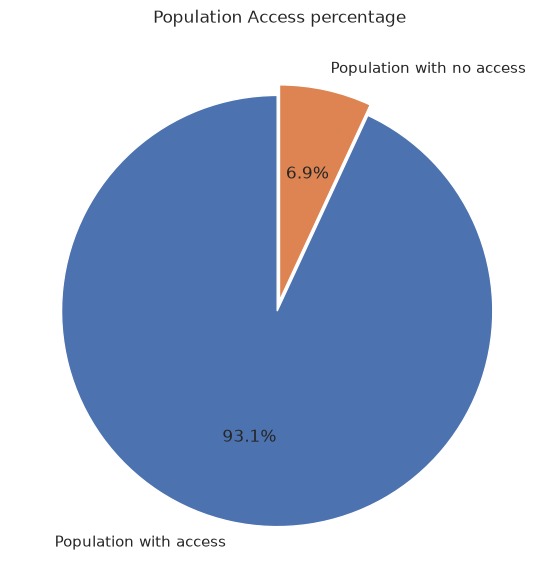

In [6]:
#calculate totals for pie chart
Access_total = df_telco['Población_Con_Acceso'].sum()
No_Access_total = df_telco['Población_Sin_Acceso'].sum()

#tags
values = [Access_total,No_Access_total]
tags = ['Population with access','Population with no access']

#visual code
sns.set_theme(style="whitegrid")
plt.figure(figsize=(7,7))
plt.pie(values, labels=tags, autopct='%1.1f%%', startangle=90, explode=(0.05,0))
plt.title('Population Access percentage')
plt.show()

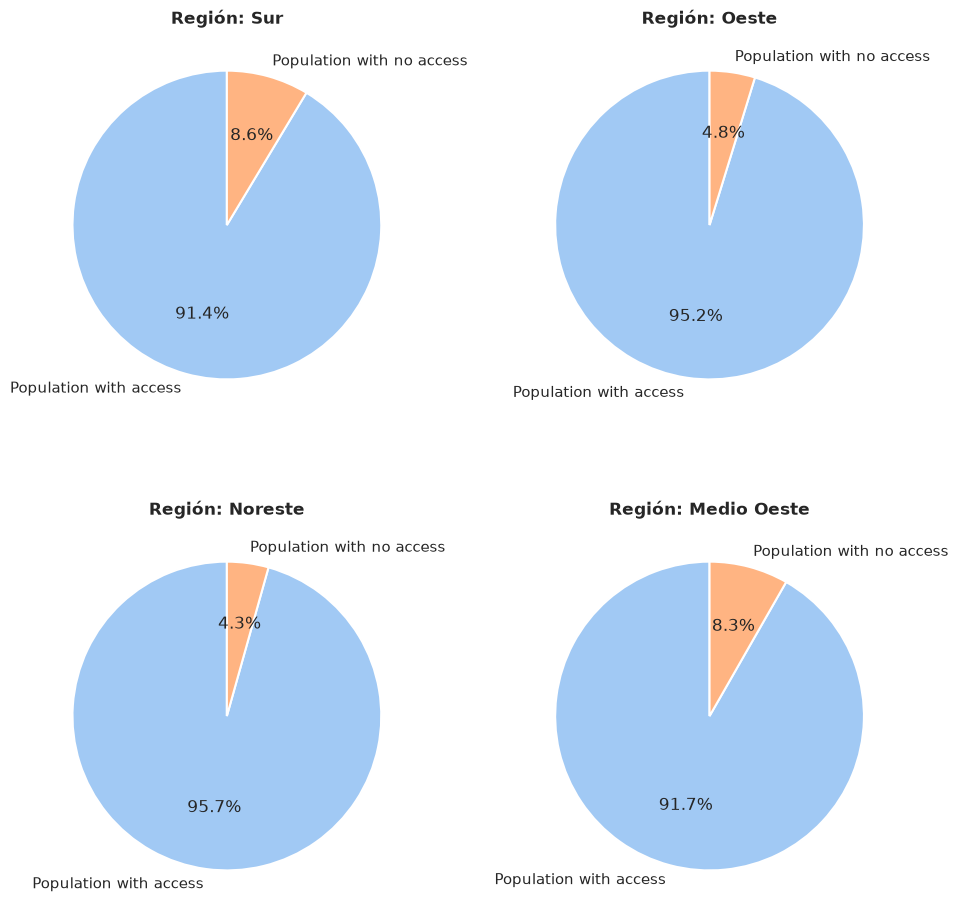

In [14]:
#retrieve regions
regiones = df_telco['Región'].unique()

#subplot code to get the 4 pie charts
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 10))
axes = axes.flatten()

# color palette
colors = sns.color_palette("pastel")[0:2]
tags = ['Population with access', 'Population with no access']

#repeat code to go trough ech region
for i, region in enumerate(regiones):
    # filter on the main df
    df_region = df_telco[df_telco['Región'] == region]
    
    # sum values by region
    con_acceso = df_region['Población_Con_Acceso'].sum()
    sin_acceso = df_region['Población_Sin_Acceso'].sum()
    
    values = [con_acceso, sin_acceso]
    
    # code for pie chart on each subplot
    axes[i].pie(
        values, 
        labels=tags, 
        autopct='%1.1f%%', 
        startangle=90, 
        colors=colors,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
    )
    
    # dinamic title by region
    axes[i].set_title(f'Región: {region}', fontsize=12, fontweight='bold')

# tight layout to fit visually
plt.tight_layout()
plt.show()